# Pipeline GPU n°2 : PyTorch → TorchScript / torch.compile → CUDA
TP1 Déploiement IA — ResNet-18 / CIFAR-10. **Environnement d'exécution Colab : GPU T4 (Exécution > Modifier le type d'exécution > T4 GPU).**

| Niveau | Composant |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné) |
| Format | TorchScript (trace + freeze) et graphe FX PyTorch 2 (TorchDynamo) |
| Middle level | optimisations JIT / compilateur TorchInductor (fusion, génération de kernels Triton) |
| Bas niveau | CUDA, cuDNN (convolutions) et kernels Triton générés |
| Matériel | GPU Google Colab (T4) |

[Ouvrir dans Colab](https://colab.research.google.com/github/Romain-LM-Dev/TP1_deploiement_IA/blob/main/notebooks/04_gpu_torchcompile.ipynb)

## Protocole (identique aux 4 pipelines, défini dans `common.py`)
- **Données** : les 50 premières images du jeu de test CIFAR-10, redimensionnées de 32×32 à 224×224 (bilinéaire) puis normalisées avec la moyenne/écart-type ImageNet.
- **Modèle** : ResNet-18 pré-entraîné ImageNet (`IMAGENET1K_V1`). Les 1000 classes sont regroupées en 10 classes CIFAR (ex. les 118 races de chiens → *dog*) ; la classe prédite est celle dont le meilleur logit est le plus élevé.
- **Mesure** : batchs de 10 images, données déjà sur le périphérique, 1 appel initial (compilation éventuelle, chronométré à part), 3 passes de chauffe, puis 10 exécutions mesurées des 50 images. Synchronisation explicite après chaque batch sur GPU.
- **Énergie** : compteur matériel (NVML sur GPU, RAPL sur CPU si accessible), intégré sur ≥ 3 s d'inférence en boucle après chaque exécution.
- **Référence** : PyTorch *eager* sur le même matériel, pour mesurer le gain et vérifier que les prédictions ne sont pas dégradées.

In [1]:
!pip install -q nvidia-ml-py
!nvidia-smi

Tue Nov  3 16:20:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Récupération du dépôt : code commun (données, modèle, protocole de mesure)
import os, subprocess, sys
REPO = "https://github.com/Romain-LM-Dev/TP1_deploiement_IA.git"
if os.path.exists("../common.py"):          # exécution locale depuis notebooks/
    os.chdir("..")
elif not os.path.exists("common.py"):       # Google Colab
    if not os.path.exists("TP1_deploiement_IA"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    os.chdir("TP1_deploiement_IA")
sys.path.insert(0, os.getcwd())
import common as C
C.env_info()

{'python': '3.13.16',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'cpu': 'Intel(R) Xeon(R) CPU @ 2.00GHz',
 'cpu_threads': 1,
 'os_cpu_count': 2,
 'gpu': 'Tesla T4',
 'cuda': '13.0',
 'cudnn': 92700}

In [3]:
import time
from collections import Counter
import numpy as np, torch
from IPython.display import display

torch.manual_seed(C.SEED)
x, y = C.load_data()            # (50, 3, 224, 224), normalisation ImageNet
model = C.load_model()          # ResNet-18 IMAGENET1K_V1, mode eval
print("Entrée :", tuple(x.shape), "| batch :", C.BATCH_SIZE, "| répétitions :", C.N_RUNS)
print("Répartition des classes :", dict(zip(C.CIFAR_CLASSES, np.bincount(y, minlength=10).tolist())))
results = []

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 194MB/s]

Entrée : (50, 3, 224, 224) | batch : 10 | répétitions : 10
Répartition des classes : {'airplane': 5, 'automobile': 3, 'bird': 2, 'cat': 3, 'deer': 5, 'dog': 7, 'frog': 9, 'horse': 4, 'ship': 4, 'truck': 8}


In [4]:
assert torch.cuda.is_available(), "Activer un GPU : Exécution > Modifier le type d'exécution"
torch.backends.cudnn.benchmark = True
meter = C.EnergyMeter("cuda")
print("Source énergie :", meter.source)
model = model.cuda()
batches = C.make_batches(x.cuda())     # données déjà sur le GPU : on mesure l'inférence seule
sync = torch.cuda.synchronize

Source énergie : NVML (GPU seul)


## 1. Référence : PyTorch eager sur GPU

In [5]:
with torch.inference_mode():
    eager = C.benchmark("GPU-2 PyTorch", "PyTorch eager (réf.)", model, batches, y, device="cuda",
                        sync=sync, meter=meter)
ref = eager["_logits"]
results.append(eager)

PyTorch eager (réf.)            829.6 ±    7.1 img/s |     60.3 ±    0.5 ms / 50 img | acc 64%


## 2. TorchScript
Trace + `freeze` + `optimize_for_inference` : poids constants, BatchNorm repliée dans les convolutions ; le fuser NVFuser/NNC peut fusionner les opérations élémentaires.

In [6]:
with torch.inference_mode():
    t0 = time.perf_counter()
    traced = torch.jit.trace(model, batches[0])
    ts = torch.jit.optimize_for_inference(torch.jit.freeze(traced))
    ts_s = time.perf_counter() - t0
kinds = lambda g: Counter(n.kind() for n in g.nodes() if n.kind().startswith("aten::"))
print(f"Trace + optimisation : {ts_s:.2f} s")
print("Graphe tracé    :", dict(kinds(traced.inlined_graph)))
print("Graphe optimisé :", dict(kinds(ts.graph)))
with torch.inference_mode():
    r = C.benchmark("GPU-2 PyTorch", "TorchScript (freeze)", ts, batches, y, device="cuda",
                    ref=ref, sync=sync, meter=meter)
r["compile_s"] = ts_s
results.append(r)

Trace + optimisation : 0.87 s
Graphe tracé    : {'aten::_convolution': 20, 'aten::batch_norm': 20, 'aten::relu_': 17, 'aten::max_pool2d': 1, 'aten::add_': 8, 'aten::adaptive_avg_pool2d': 1, 'aten::flatten': 1, 'aten::linear': 1}
Graphe optimisé : {'aten::cudnn_convolution_relu': 9, 'aten::max_pool2d': 1, 'aten::cudnn_convolution_add_relu': 8, 'aten::conv2d': 3, 'aten::adaptive_avg_pool2d': 1, 'aten::flatten': 1, 'aten::matmul': 1, 'aten::add': 1}
TorchScript (freeze)            915.9 ±   13.6 img/s |     54.6 ±    0.8 ms / 50 img | acc 64% | accord eager 100%, max|Δlogit| 5.01e-05


## 3. torch.compile (TorchInductor)
TorchDynamo capture le graphe, TorchInductor génère des kernels **Triton** pour les opérations élémentaires fusionnées (BN+ReLU, Add+ReLU…) et appelle cuDNN pour les convolutions. `freezing=True` permet de replier les BatchNorm dans les poids des convolutions. La compilation a lieu au premier appel (`first_call_s`).

In [7]:
import torch._dynamo, torch._inductor.config
torch._inductor.config.freezing = True
expl = torch._dynamo.explain(model)(batches[0])
print(f"Graphes capturés : {expl.graph_count} | ruptures de graphe : {expl.graph_break_count} | opérations : {expl.op_count}")
torch._dynamo.reset()
compiled = torch.compile(model)
with torch.inference_mode():
    r = C.benchmark("GPU-2 PyTorch", "torch.compile (inductor)", compiled, batches, y, device="cuda",
                    ref=ref, sync=sync, meter=meter)
results.append(r)

Graphes capturés : 1 | ruptures de graphe : 0 | opérations : 69


W1103 16:22:31.742000 3160 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


torch.compile (inductor)        538.6 ±    8.4 img/s |     92.9 ±    1.5 ms / 50 img | acc 64% | accord eager 100%, max|Δlogit| 4.67e-05


## 4. Synthèse, graphiques et sauvegarde

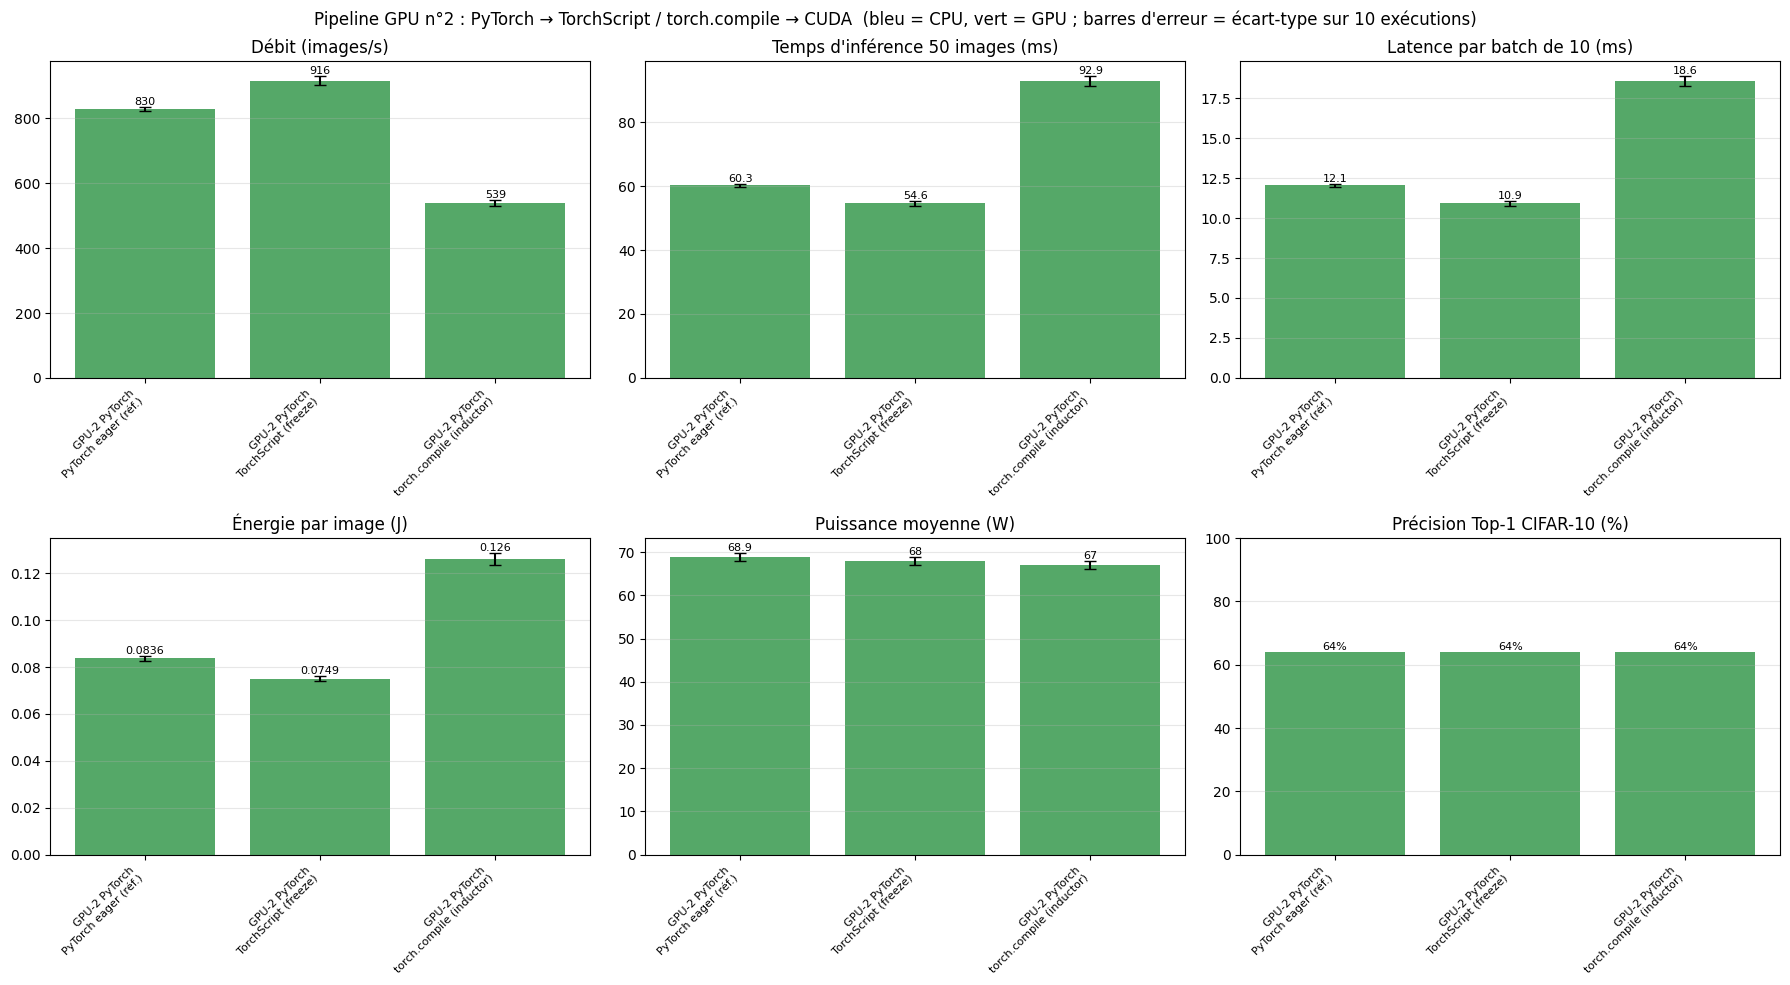

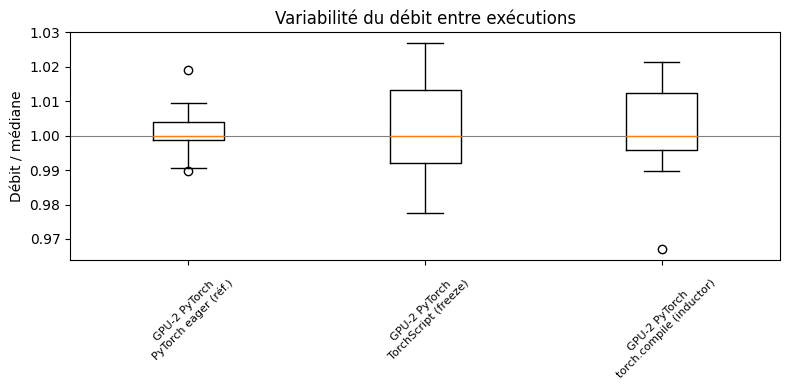

,0,1,2
pipeline,GPU-2 PyTorch,GPU-2 PyTorch,GPU-2 PyTorch
variant,PyTorch eager (réf.),TorchScript (freeze),torch.compile (inductor)
throughput_mean,829.6055,915.8903,538.5836
throughput_std,7.0977,13.645,8.3571
throughput_min,820.1458,893.567,520.3853
throughput_max,844.419,938.7224,549.6038
throughput_cv_pct,0.8555,1.4898,1.5517
total_ms_mean,60.2736,54.6026,92.8565
total_ms_std,0.5129,0.8125,1.4594
total_ms_min,59.2123,53.2639,90.9746


Résultats écrits dans results/04_gpu_torchcompile.json


[résultats 04_gpu_torchcompile intégrés au notebook]

In [8]:
df = C.plot_summary(results, "Pipeline GPU n°2 : PyTorch → TorchScript / torch.compile → CUDA", "figures/04_gpu_torchcompile.png")
display(df[C.TABLE_COLS].round(4).T)
path = C.save_results("04_gpu_torchcompile", results, {})

In [9]:
# Colab dans le navigateur : télécharge le JSON (à déposer dans results/ du dépôt).
# Extension Colab de VS Code : rien à faire, il suffit d'enregistrer le notebook (résultats intégrés ci-dessus).
try:
    from google.colab import files
    files.download(path)
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lecture des résultats
- **Débit / temps** : comparer chaque variante à la référence *eager* de ce notebook (même machine, même session).
- **Stabilité** : un coefficient de variation (`throughput_cv_pct`) < 5 % indique des mesures reproductibles ; au-delà, regarder le *boxplot* (valeurs aberrantes = interférences de la VM partagée).
- **Qualité** : `agreement_vs_eager` doit valoir 100 % et `max_abs_diff_vs_eager` rester faible (~1e-4 en FP32).
- L'analyse croisée des 4 pipelines est faite dans `05_comparaison.ipynb` et dans le rapport.